Perceive

   ↓

Update Beliefs

   ↓

Generate Desires

   ↓

Select Intention

   ↓

Create Plan
   
   ↓

Execute

   ↓

Reconsider

In [17]:

import random
from collections import deque


# ============================================================
# TILEWORLD ENVIRONMENT
# ============================================================

GRID_SIZE = 15


class TileWorld:
    def __init__(self, hole_probability=0.08,
                 min_lifetime=4, max_lifetime=12,
                 world_ticks_per_action=2, seed=None):

        self.size = GRID_SIZE
        self.hole_probability = hole_probability
        self.min_lifetime = min_lifetime
        self.max_lifetime = max_lifetime
        self.world_ticks_per_action = world_ticks_per_action

        self.random = random.Random(seed)

        # {(row, col): remaining_lifetime}
        self.holes = {}

        self.holes_appeared = 0
        self.holes_filled = 0

    def valid_cells(self):
        return [
            (r, c)
            for r in range(self.size)
            for c in range(self.size)
        ]

    def advance_one_tick(self):
        """
        Advance the environment by one world tick.
        Existing holes lose lifetime.
        New holes may appear.
        """

        # Decrease hole lifetime
        expired = []

        for position in self.holes:
            self.holes[position] -= 1

            if self.holes[position] <= 0:
                expired.append(position)

        # Remove expired holes
        for position in expired:
            del self.holes[position]

        # Possibly create a new hole
        if self.random.random() < self.hole_probability:

            empty_cells = [
                cell
                for cell in self.valid_cells()
                if cell not in self.holes
            ]

            if empty_cells:
                position = self.random.choice(empty_cells)

                lifetime = self.random.randint(
                    self.min_lifetime,
                    self.max_lifetime
                )

                self.holes[position] = lifetime
                self.holes_appeared += 1

    def advance(self):
        """
        Advance the world according to the configured
        number of world ticks per agent action.
        """

        for _ in range(self.world_ticks_per_action):
            self.advance_one_tick()

    def percept(self):
        """
        Return the currently visible environment.
        """

        return {
            "holes": set(self.holes.keys())
        }

    def fill_hole(self, position):

        if position in self.holes:
            del self.holes[position]
            self.holes_filled += 1
            return True

        return False


# ============================================================
# BDI AGENT
# ============================================================

class BDIAgent:

    def __init__(self, start=(0, 0), gamma=1,
                 commitment="single-minded"):

        self.position = start

        # BELIEFS
        self.beliefs = {
            "holes": set()
        }

        # DESIRES
        self.desires = []

        # INTENTION
        self.intention = None

        # PLAN
        self.plan_actions = deque()

        # Reconsideration interval
        self.gamma = gamma

        # Number of actions since reconsideration
        self.actions_since_reconsideration = 0

        self.commitment = commitment

        self.trace = []

    # --------------------------------------------------------
    # BELIEF REVISION FUNCTION
    # brf(B, p)
    # --------------------------------------------------------

    def brf(self, percept):

        self.beliefs["holes"] = set(percept["holes"])

        return self.beliefs

    # --------------------------------------------------------
    # OPTIONS FUNCTION
    # options(B, I)
    # --------------------------------------------------------

    def options(self):

        # Every visible hole becomes a possible desire
        self.desires = list(self.beliefs["holes"])

        return self.desires

    # --------------------------------------------------------
    # FILTER FUNCTION
    # filter(B, D, I)
    # --------------------------------------------------------

    def filter(self, desires):

        if not desires:
            return None

        # Choose nearest hole
        best = min(
            desires,
            key=lambda hole:
            self.manhattan_distance(self.position, hole)
        )

        return best

    # --------------------------------------------------------
    # PLAN FUNCTION
    # plan(B, I)
    # --------------------------------------------------------

    def make_plan(self, goal):

        if goal is None:
            return deque()

        return self.shortest_path(
            self.position,
            goal
        )

    # --------------------------------------------------------
    # MANHATTAN DISTANCE
    # --------------------------------------------------------

    def manhattan_distance(self, a, b):

        return (
            abs(a[0] - b[0]) +
            abs(a[1] - b[1])
        )

    # --------------------------------------------------------
    # SHORTEST PATH
    # --------------------------------------------------------

    def shortest_path(self, start, goal):

        queue = deque([start])

        parent = {
            start: None
        }

        while queue:

            current = queue.popleft()

            if current == goal:
                break

            for neighbour in self.neighbours(current):

                if neighbour not in parent:

                    parent[neighbour] = current
                    queue.append(neighbour)

        # Goal cannot be reached
        if goal not in parent:
            return deque()

        # Reconstruct path
        path = []

        current = goal

        while current != start:

            previous = parent[current]

            path.append(current)

            current = previous

        path.reverse()

        return deque(path)

    # --------------------------------------------------------
    # NEIGHBOURS
    # --------------------------------------------------------

    def neighbours(self, position):

        r, c = position

        candidates = [
            (r - 1, c),
            (r + 1, c),
            (r, c - 1),
            (r, c + 1)
        ]

        valid = []

        for nr, nc in candidates:

            if (
                0 <= nr < GRID_SIZE
                and
                0 <= nc < GRID_SIZE
            ):
                valid.append((nr, nc))

        return valid

    # --------------------------------------------------------
    # COMMIT TO AN INTENTION
    # --------------------------------------------------------

    def commit(self):

        desires = self.options()

        if not desires:

            self.intention = None
            self.plan_actions = deque()

            return

        new_intention = self.filter(desires)

        self.intention = new_intention

        self.plan_actions = self.make_plan(
            self.intention
        )

        self.trace.append(
            f"COMMIT: pursuing hole {self.intention}"
        )

    # --------------------------------------------------------
    # CHECK IF INTENTION IS ACHIEVED
    # --------------------------------------------------------

    def intention_achieved(self):

        return (
            self.intention is not None
            and
            self.position == self.intention
            and
            self.intention not in self.beliefs["holes"]
        )

    # --------------------------------------------------------
    # CHECK IF INTENTION IS STILL ACHIEVABLE
    # --------------------------------------------------------

    def intention_achievable(self):

        if self.intention is None:
            return False

        # In this Tileworld, if the hole still exists,
        # it is considered achievable.
        return (
            self.intention
            in self.beliefs["holes"]
        )

    # --------------------------------------------------------
    # DROP INTENTION
    # --------------------------------------------------------

    def drop_intention(self):

        if self.intention is not None:

            self.trace.append(
                f"DROP: hole {self.intention} "
                f"is no longer achievable"
            )

        self.intention = None

        self.plan_actions = deque()

    # --------------------------------------------------------
    # RECONSIDERATION
    # --------------------------------------------------------

    def reconsider(self, world):

        # If gamma has not been reached,
        # continue current intention
        if self.actions_since_reconsideration < self.gamma:
            return

        self.actions_since_reconsideration = 0

        # Deliberation has a cost:
        # the agent spends one time step thinking,
        # while the world continues changing.
        world.advance()

        # Re-perceive environment
        percept = world.percept()

        self.brf(percept)

        # Single-minded commitment:
        # drop intention if impossible
        if (
            self.commitment == "single-minded"
            and
            self.intention is not None
            and
            not self.intention_achievable()
        ):

            self.drop_intention()
            return

        # Open-minded behaviour:
        # compare current intention with best option
        desires = self.options()

        if not desires:
            return

        preferred = self.filter(desires)

        if (
            self.commitment == "open-minded"
            and
            preferred != self.intention
        ):

            old = self.intention

            self.intention = preferred

            self.plan_actions = self.make_plan(
                preferred
            )

            self.trace.append(
                f"SWITCH: {old} -> {preferred}"
            )

    # --------------------------------------------------------
    # EXECUTE ONE ACTION
    # --------------------------------------------------------

    def execute_action(self, world):

        if not self.plan_actions:
            return False

        next_position = self.plan_actions.popleft()

        self.position = next_position

        self.actions_since_reconsideration += 1

        # Fill hole if agent reaches it
        if world.fill_hole(self.position):

            self.trace.append(
                f"ACHIEVE: filled hole "
                f"at {self.position}"
            )

            # Update beliefs
            self.brf(world.percept())

            self.intention = None

            self.plan_actions = deque()

        # World changes while agent acts
        world.advance()

        return True

    # --------------------------------------------------------
    # ONE BDI CYCLE
    # --------------------------------------------------------

    def step(self, world):

        # ----------------------------------------------------
        # Perceive and revise beliefs
        # ----------------------------------------------------

        percept = world.percept()

        self.brf(percept)

        # ----------------------------------------------------
        # Commit if there is no current intention
        # ----------------------------------------------------

        if self.intention is None:

            self.commit()

            # No hole available
            if self.intention is None:

                world.advance()

                return

        # ----------------------------------------------------
        # If intention disappeared before execution
        # ----------------------------------------------------

        if not self.intention_achievable():

            self.drop_intention()

            return

        # ----------------------------------------------------
        # Execute action
        # ----------------------------------------------------

        self.execute_action(world)

        # ----------------------------------------------------
        # Reconsider intention
        # ----------------------------------------------------

        self.reconsider(world)


# ============================================================
# SIMULATION
# ============================================================

def run_simulation(
    gamma=2,
    commitment="single-minded",
    agent_steps=100,
    world_speed=2,
    seed=42
):

    world = TileWorld(
        hole_probability=0.10,
        min_lifetime=4,
        max_lifetime=12,
        world_ticks_per_action=world_speed,
        seed=seed
    )

    agent = BDIAgent(
        start=(0, 0),
        gamma=gamma,
        commitment=commitment
    )

    for step in range(agent_steps):

        agent.step(world)

    effectiveness = 0

    if world.holes_appeared > 0:

        effectiveness = (
            world.holes_filled /
            world.holes_appeared
        )

    return {
        "gamma": gamma,
        "commitment": commitment,
        "holes_filled": world.holes_filled,
        "holes_appeared": world.holes_appeared,
        "effectiveness": effectiveness,
        "trace": agent.trace
    }


# ============================================================
# MAIN PROGRAM
# ============================================================

if __name__ == "__main__":

    result = run_simulation(
        gamma=2,
        commitment="single-minded",
        agent_steps=100,
        world_speed=2,
        seed=42
    )

    print("\n========== BDI TILEWORLD RESULT ==========\n")

    print("Commitment Strategy:",
          result["commitment"])

    print("Gamma:",
          result["gamma"])

    print("Holes Filled:",
          result["holes_filled"])

    print("Holes Appeared:",
          result["holes_appeared"])

    print(
        "Effectiveness:",
        round(
            result["effectiveness"],
            3
        )
    )

    print("\n========== EVENT TRACE ==========\n")

    for event in result["trace"]:

        print(event)




========== BDI TILEWORLD RESULT ==========

Commitment Strategy: single-minded
Gamma: 2
Holes Filled: 2
Holes Appeared: 25
Effectiveness: 0.08

========== EVENT TRACE ==========

COMMIT: pursuing hole (4, 10)
DROP: hole (4, 10) is no longer achievable
COMMIT: pursuing hole (3, 5)
DROP: hole (3, 5) is no longer achievable
COMMIT: pursuing hole (7, 12)
DROP: hole (7, 12) is no longer achievable
COMMIT: pursuing hole (3, 13)
DROP: hole (3, 13) is no longer achievable
COMMIT: pursuing hole (10, 12)
DROP: hole (10, 12) is no longer achievable
COMMIT: pursuing hole (14, 0)
DROP: hole (14, 0) is no longer achievable
COMMIT: pursuing hole (9, 10)
DROP: hole (9, 10) is no longer achievable
COMMIT: pursuing hole (12, 4)
DROP: hole (12, 4) is no longer achievable
COMMIT: pursuing hole (12, 7)
ACHIEVE: filled hole at (12, 7)
COMMIT: pursuing hole (0, 5)
DROP: hole (0, 5) is no longer achievable
COMMIT: pursuing hole (4, 1)
DROP: hole (4, 1) is no longer achievable
COMMIT: pursuing hole (7, 5)
ACH

Reactive agent: Maps percepts directly to actions without long-term goal deliberation.

Deliberative agent: Reasons about goals and plans before acting.

Belief: Information the agent currently considers true about the environment.

Desire: A possible goal. Multiple desires can exist simultaneously.

Intention: A desire that the agent has committed to achieving.

Plan: A sequence of actions used to achieve an intention.

BDI: Belief–Desire–Intention architecture.

Belief revision function (brf): Updates beliefs using new percepts.

Options function: Generates possible desires from the current beliefs.

Filter function: Selects one desire and converts it into an intention.

Means–ends reasoning: Finding actions that transform the current state into the goal state.

Commitment: The policy controlling how strongly an agent continues pursuing an intention.

Blind commitment: Keeps an intention until it is achieved.

Single-minded commitment: Keeps an intention until achieved or believed impossible.

Open-minded commitment: Continually checks whether a better option exists and can change intention.

Reconsideration interval (γ): Number of actions performed before reconsidering the current intention.

Cautious agent: Small γ, especially γ = 1.

Bold agent: Very large γ, meaning it rarely reconsiders.

World dynamism: The rate at which the environment changes.

Effectiveness:

Effectiveness = Holes Filled / Holes Appeared


========== MAIN EXPERIMENT ==========
Gamma: 2
World speed: 2
Holes appeared: 25
Holes filled: 2
Effectiveness: 0.08

========== EVENT TRACE ==========
COMMIT -> (4, 10)
DROP -> (4, 10) disappeared
COMMIT -> (3, 5)
DROP -> (3, 5) disappeared
COMMIT -> (7, 12)
DROP -> (7, 12) disappeared
COMMIT -> (3, 13)
DROP -> (3, 13) disappeared
COMMIT -> (10, 12)
DROP -> (10, 12) disappeared
COMMIT -> (14, 0)
DROP -> (14, 0) disappeared
COMMIT -> (9, 10)
DROP -> (9, 10) disappeared
COMMIT -> (12, 4)
DROP -> (12, 4) disappeared
COMMIT -> (12, 7)
ACHIEVE -> filled (12, 7)
COMMIT -> (0, 5)
DROP -> (0, 5) disappeared
COMMIT -> (4, 1)
DROP -> (4, 1) disappeared
COMMIT -> (7, 5)
ACHIEVE -> filled (7, 5)
COMMIT -> (6, 13)
DROP -> (6, 13) disappeared
COMMIT -> (13, 11)
DROP -> (13, 11) disappeared
COMMIT -> (9, 14)
DROP -> (9, 14) disappeared
COMMIT -> (7, 12)
DROP -> (7, 12) disappeared
COMMIT -> (3, 9)
DROP -> (3, 9) disappeared
COMMIT -> (13, 14)


EXERCISE 1: BOLDNESS AGAINST DYNAMISM

Average Effecti

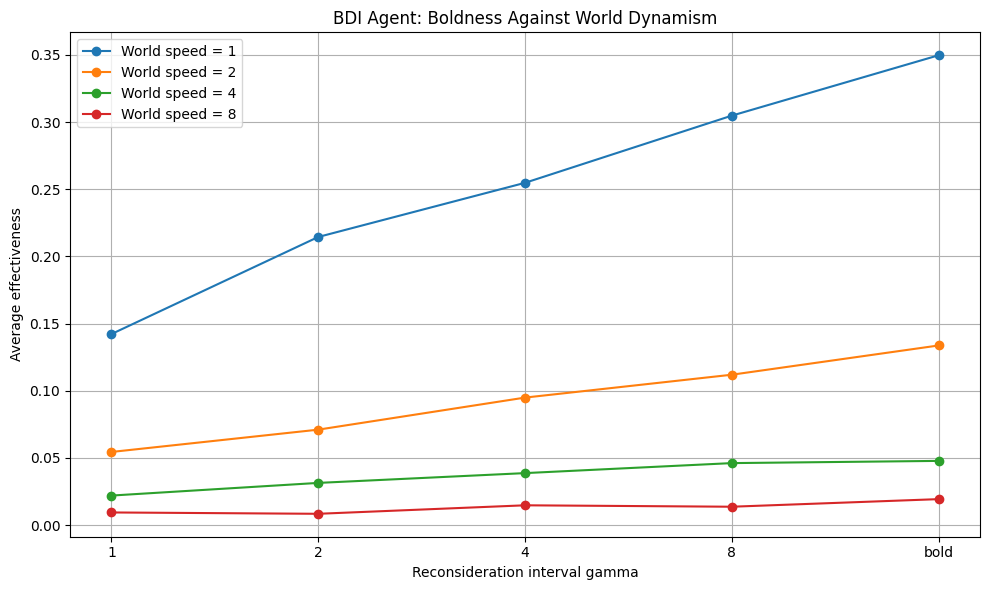



EXERCISE 2: RESOURCE-BOUNDED FILTER

BATTERY-AWARE BDI AGENT
Holes filled: 0
Holes appeared: 6
Steps stranded: 0
Final battery: 26

BATTERY-BLIND AGENT
Holes filled: 0
Holes appeared: 6
Steps stranded: 0
Final battery: 26

========== COMPARISON ==========
Agent                    Holes Filled        Stranded Steps      
-----------------------------------------------------------------
Battery-Aware BDI        0                   0                   
Battery-Blind            0                   0                   


In [19]:

import random
import time
from collections import deque

import matplotlib.pyplot as plt


# ============================================================
# GLOBAL CONSTANTS
# ============================================================

GRID_SIZE = 15


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def valid_neighbours(position, grid_size=GRID_SIZE):

    r, c = position

    candidates = [
        (r - 1, c),
        (r + 1, c),
        (r, c - 1),
        (r, c + 1)
    ]

    return [
        (nr, nc)
        for nr, nc in candidates
        if 0 <= nr < grid_size
        and 0 <= nc < grid_size
    ]


def shortest_path(start, goal):

    if start == goal:
        return deque()

    queue = deque([start])
    parent = {start: None}

    while queue:

        current = queue.popleft()

        if current == goal:
            break

        for nxt in valid_neighbours(current):

            if nxt not in parent:
                parent[nxt] = current
                queue.append(nxt)

    if goal not in parent:
        return deque()

    path = []
    current = goal

    while current != start:

        path.append(current)
        current = parent[current]

    path.reverse()

    return deque(path)


# ============================================================
# TILEWORLD ENVIRONMENT
# ============================================================

class TileWorld:

    def __init__(
        self,
        hole_probability=0.08,
        min_lifetime=4,
        max_lifetime=12,
        world_ticks_per_action=1,
        seed=None
    ):

        self.size = GRID_SIZE

        self.hole_probability = hole_probability
        self.min_lifetime = min_lifetime
        self.max_lifetime = max_lifetime

        self.world_ticks_per_action = world_ticks_per_action

        self.random = random.Random(seed)

        # position -> remaining lifetime
        self.holes = {}

        self.holes_appeared = 0
        self.holes_filled = 0

    def all_cells(self):

        return [
            (r, c)
            for r in range(self.size)
            for c in range(self.size)
        ]

    def advance_one_tick(self):

        expired = []

        for hole in list(self.holes.keys()):

            self.holes[hole] -= 1

            if self.holes[hole] <= 0:
                expired.append(hole)

        for hole in expired:
            del self.holes[hole]

        # New hole may appear
        if self.random.random() < self.hole_probability:

            available = [
                cell
                for cell in self.all_cells()
                if cell not in self.holes
            ]

            if available:

                position = self.random.choice(available)

                lifetime = self.random.randint(
                    self.min_lifetime,
                    self.max_lifetime
                )

                self.holes[position] = lifetime

                self.holes_appeared += 1

    def advance(self):

        for _ in range(self.world_ticks_per_action):
            self.advance_one_tick()

    def percept(self):

        return {
            "holes": set(self.holes.keys())
        }

    def fill_hole(self, position):

        if position in self.holes:

            del self.holes[position]

            self.holes_filled += 1

            return True

        return False


# ============================================================
# BDI AGENT
# ============================================================

class BDIAgent:

    def __init__(
        self,
        start=(0, 0),
        gamma=1,
        commitment="single-minded"
    ):

        self.position = start

        # BELIEFS
        self.beliefs = {
            "holes": set()
        }

        # DESIRES
        self.desires = []

        # INTENTION
        self.intention = None

        # PLAN
        self.plan_actions = deque()

        # Commitment parameter
        self.gamma = gamma

        # Number of actions since last reconsideration
        self.actions_since_reconsideration = 0

        self.commitment = commitment

        self.trace = []

    # --------------------------------------------------------
    # BDI: BELIEF REVISION FUNCTION
    # brf(B, p)
    # --------------------------------------------------------

    def brf(self, percept):

        self.beliefs["holes"] = set(percept["holes"])

        return self.beliefs

    # --------------------------------------------------------
    # BDI: OPTIONS FUNCTION
    # options(B, I)
    # --------------------------------------------------------

    def options(self):

        self.desires = list(
            self.beliefs["holes"]
        )

        return self.desires

    # --------------------------------------------------------
    # BDI: FILTER FUNCTION
    # filter(B, D, I)
    # --------------------------------------------------------

    def filter(self, desires):

        if not desires:
            return None

        return min(
            desires,
            key=lambda hole:
            manhattan(self.position, hole)
        )

    # --------------------------------------------------------
    # BDI: PLAN FUNCTION
    # --------------------------------------------------------

    def plan(self, intention):

        if intention is None:
            return deque()

        return shortest_path(
            self.position,
            intention
        )

    # --------------------------------------------------------
    # COMMIT
    # --------------------------------------------------------

    def commit(self):

        desires = self.options()

        if not desires:

            self.intention = None
            self.plan_actions = deque()

            return

        self.intention = self.filter(desires)

        self.plan_actions = self.plan(
            self.intention
        )

        self.trace.append(
            f"COMMIT -> {self.intention}"
        )

    # --------------------------------------------------------
    # CHECK ACHIEVABILITY
    # --------------------------------------------------------

    def intention_achievable(self):

        return (
            self.intention is not None
            and
            self.intention in self.beliefs["holes"]
        )

    # --------------------------------------------------------
    # DROP INTENTION
    # --------------------------------------------------------

    def drop_intention(self):

        if self.intention is not None:

            self.trace.append(
                f"DROP -> {self.intention} disappeared"
            )

        self.intention = None

        self.plan_actions = deque()

    # --------------------------------------------------------
    # EXECUTE ONE ACTION
    # --------------------------------------------------------

    def execute_action(self, world):

        if not self.plan_actions:
            return False

        next_position = self.plan_actions.popleft()

        self.position = next_position

        self.actions_since_reconsideration += 1

        if world.fill_hole(self.position):

            self.trace.append(
                f"ACHIEVE -> filled {self.position}"
            )

            self.intention = None
            self.plan_actions = deque()

        world.advance()

        return True

    # --------------------------------------------------------
    # RECONSIDERATION
    # --------------------------------------------------------

    def reconsider(self, world):

        if self.gamma == "bold":
            return

        if (
            self.actions_since_reconsideration
            < self.gamma
        ):
            return

        self.actions_since_reconsideration = 0

        # Deliberation costs one agent time step.
        # World changes while agent thinks.
        world.advance()

        percept = world.percept()

        self.brf(percept)

        # SINGLE-MINDED:
        # Drop intention only if impossible.
        if (
            self.intention is not None
            and
            not self.intention_achievable()
        ):

            self.drop_intention()

            return

        # OPEN-MINDED:
        # Switch if a better option exists.
        if self.commitment == "open-minded":

            desires = self.options()

            if desires:

                preferred = self.filter(desires)

                if (
                    preferred != self.intention
                ):

                    old = self.intention

                    self.intention = preferred

                    self.plan_actions = self.plan(
                        preferred
                    )

                    self.trace.append(
                        f"SWITCH -> {old} to {preferred}"
                    )

    # --------------------------------------------------------
    # COMPLETE BDI STEP
    # --------------------------------------------------------

    def step(self, world):

        # PERCEIVE
        percept = world.percept()

        # BELIEF REVISION
        self.brf(percept)

        # No intention -> deliberate and commit
        if self.intention is None:

            self.commit()

            if self.intention is None:

                world.advance()

                return

        # If current goal disappeared
        if not self.intention_achievable():

            self.drop_intention()

            return

        # Execute plan
        self.execute_action(world)

        # Reconsider according to gamma
        self.reconsider(world)


# ============================================================
# MAIN EXPERIMENT
# ============================================================

def run_simulation(
    gamma=2,
    commitment="single-minded",
    agent_steps=100,
    world_speed=2,
    seed=42,
    show_trace=True
):

    world = TileWorld(
        hole_probability=0.10,
        min_lifetime=4,
        max_lifetime=12,
        world_ticks_per_action=world_speed,
        seed=seed
    )

    agent = BDIAgent(
        start=(0, 0),
        gamma=gamma,
        commitment=commitment
    )

    for _ in range(agent_steps):

        agent.step(world)

    effectiveness = 0

    if world.holes_appeared > 0:

        effectiveness = (
            world.holes_filled
            / world.holes_appeared
        )

    result = {
        "gamma": gamma,
        "world_speed": world_speed,
        "holes_filled": world.holes_filled,
        "holes_appeared": world.holes_appeared,
        "effectiveness": effectiveness,
        "trace": agent.trace
    }

    if show_trace:

        print("\n========== MAIN EXPERIMENT ==========")

        print("Gamma:", gamma)

        print(
            "World speed:",
            world_speed
        )

        print(
            "Holes appeared:",
            world.holes_appeared
        )

        print(
            "Holes filled:",
            world.holes_filled
        )

        print(
            "Effectiveness:",
            round(effectiveness, 3)
        )

        print("\n========== EVENT TRACE ==========")

        for event in agent.trace:

            print(event)

    return result


# ============================================================
# EXERCISE 1
# BOLDNESS AGAINST DYNAMISM
# ============================================================

def exercise_1():

    gammas = [1, 2, 4, 8, "bold"]

    world_speeds = [1, 2, 4, 8]

    seeds = range(25)

    agent_steps = 600

    results = {}

    print("\n")
    print("=" * 65)
    print("EXERCISE 1: BOLDNESS AGAINST DYNAMISM")
    print("=" * 65)

    for speed in world_speeds:

        results[speed] = {}

        for gamma in gammas:

            effectiveness_values = []

            for seed in seeds:

                result = run_simulation(
                    gamma=gamma,
                    commitment="single-minded",
                    agent_steps=agent_steps,
                    world_speed=speed,
                    seed=seed,
                    show_trace=False
                )

                effectiveness_values.append(
                    result["effectiveness"]
                )

            average = (
                sum(effectiveness_values)
                / len(effectiveness_values)
            )

            results[speed][gamma] = average

    # --------------------------------------------------------
    # PRINT TABLE
    # --------------------------------------------------------

    print(
        "\nAverage Effectiveness "
        "(25 seeds, 600 agent steps)"
    )

    header = (
        f"{'World Speed':<15}"
        f"{'Gamma':<15}"
        f"{'Avg Effectiveness':<20}"
    )

    print("\n" + header)

    print("-" * len(header))

    for speed in world_speeds:

        for gamma in gammas:

            print(
                f"{speed:<15}"
                f"{str(gamma):<15}"
                f"{results[speed][gamma]:<20.4f}"
            )

    # --------------------------------------------------------
    # BEST GAMMA FOR EACH WORLD SPEED
    # --------------------------------------------------------

    print(
        "\n========== BEST GAMMA =========="
    )

    best_gammas = {}

    for speed in world_speeds:

        best_gamma = max(
            results[speed],
            key=results[speed].get
        )

        best_value = (
            results[speed][best_gamma]
        )

        best_gammas[speed] = best_gamma

        print(
            f"World speed {speed}: "
            f"best gamma = {best_gamma}, "
            f"effectiveness = {best_value:.4f}"
        )

    # --------------------------------------------------------
    # PLOT
    # --------------------------------------------------------

    gamma_labels = [
        str(gamma)
        for gamma in gammas
    ]

    plt.figure(figsize=(10, 6))

    for speed in world_speeds:

        values = [
            results[speed][gamma]
            for gamma in gammas
        ]

        plt.plot(
            gamma_labels,
            values,
            marker="o",
            label=f"World speed = {speed}"
        )

    plt.xlabel(
        "Reconsideration interval gamma"
    )

    plt.ylabel(
        "Average effectiveness"
    )

    plt.title(
        "BDI Agent: Boldness Against World Dynamism"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        "exercise1_gamma_vs_dynamism.png"
    )

    plt.show()

    return results, best_gammas


# ============================================================
# EXERCISE 2
# RESOURCE-BOUNDED BDI AGENT
# ============================================================

class BatteryBDIAgent(BDIAgent):

    def __init__(
        self,
        start=(0, 0),
        charger=(0, 0),
        gamma=2,
        battery_capacity=40,
        battery_aware=True
    ):

        super().__init__(
            start=start,
            gamma=gamma,
            commitment="single-minded"
        )

        self.charger = charger

        self.battery_capacity = (
            battery_capacity
        )

        self.battery = (
            battery_capacity
        )

        self.battery_aware = (
            battery_aware
        )

        self.stranded_steps = 0

        # Intentions can now be:
        # ("hole", position)
        # ("recharge", charger_position)

        self.intention_type = None

    # --------------------------------------------------------
    # RESOURCE-BOUNDED FILTER
    # --------------------------------------------------------

    def filter(self, desires):

        # ----------------------------------------------------
        # BATTERY BLIND AGENT
        # ----------------------------------------------------

        if not self.battery_aware:

            if not desires:
                return (
                    "recharge",
                    self.charger
                )

            nearest = min(
                desires,
                key=lambda hole:
                manhattan(
                    self.position,
                    hole
                )
            )

            return (
                "hole",
                nearest
            )

        # ----------------------------------------------------
        # BATTERY-AWARE AGENT
        # ----------------------------------------------------

        reachable_holes = []

        for hole in desires:

            # Battery needed:
            # current position -> hole
            # +
            # hole -> charger

            trip_to_hole = manhattan(
                self.position,
                hole
            )

            return_trip = manhattan(
                hole,
                self.charger
            )

            total_required = (
                trip_to_hole
                + return_trip
            )

            if (
                total_required
                <= self.battery
            ):

                reachable_holes.append(
                    hole
                )

        # fill-hole plan schema
        if reachable_holes:

            nearest = min(
                reachable_holes,
                key=lambda hole:
                manhattan(
                    self.position,
                    hole
                )
            )

            return (
                "hole",
                nearest
            )

        # recharge plan schema
        return (
            "recharge",
            self.charger
        )

    # --------------------------------------------------------
    # COMMIT
    # --------------------------------------------------------

    def commit(self):

        desires = self.options()

        selected = self.filter(
            desires
        )

        self.intention_type = selected[0]

        self.intention = selected[1]

        self.plan_actions = shortest_path(
            self.position,
            self.intention
        )

        self.trace.append(
            f"COMMIT -> "
            f"{self.intention_type} "
            f"{self.intention}"
        )

    # --------------------------------------------------------
    # EXECUTE ACTION
    # --------------------------------------------------------

    def execute_action(self, world):

        # Already stranded
        if self.battery <= 0:

            self.stranded_steps += 1

            world.advance()

            return False

        # Already at charger
        if (
            self.intention_type == "recharge"
            and
            self.position == self.charger
        ):

            self.battery = (
                self.battery_capacity
            )

            self.trace.append(
                "ACHIEVE -> recharged battery"
            )

            self.intention = None

            self.intention_type = None

            self.plan_actions = deque()

            world.advance()

            return True

        if not self.plan_actions:

            return False

        next_position = (
            self.plan_actions.popleft()
        )

        self.position = next_position

        # Each move costs one battery unit
        self.battery -= 1

        self.actions_since_reconsideration += 1

        # ----------------------------------------------------
        # FILL HOLE
        # ----------------------------------------------------

        if (
            self.intention_type == "hole"
            and
            world.fill_hole(
                self.position
            )
        ):

            self.trace.append(
                f"ACHIEVE -> filled "
                f"{self.position}"
            )

            self.intention = None

            self.intention_type = None

            self.plan_actions = deque()

        # ----------------------------------------------------
        # RECHARGE
        # ----------------------------------------------------

        elif (
            self.intention_type == "recharge"
            and
            self.position == self.charger
        ):

            self.battery = (
                self.battery_capacity
            )

            self.trace.append(
                "ACHIEVE -> recharged battery"
            )

            self.intention = None

            self.intention_type = None

            self.plan_actions = deque()

        world.advance()

        return True

    # --------------------------------------------------------
    # STEP
    # --------------------------------------------------------

    def step(self, world):

        percept = world.percept()

        self.brf(percept)

        # Battery blind agent is stranded
        if self.battery <= 0:

            self.stranded_steps += 1

            world.advance()

            return

        # No current intention
        if self.intention is None:

            self.commit()

        # Execute one action
        self.execute_action(world)


# ============================================================
# RUN RESOURCE EXPERIMENT
# ============================================================

def run_battery_experiment(
    battery_aware=True,
    agent_steps=300,
    seed=42
):

    world = TileWorld(
        hole_probability=0.10,
        min_lifetime=8,
        max_lifetime=20,
        world_ticks_per_action=2,
        seed=seed
    )

    agent = BatteryBDIAgent(
        start=(0, 0),
        charger=(0, 0),
        gamma=2,
        battery_capacity=40,
        battery_aware=battery_aware
    )

    for _ in range(agent_steps):

        agent.step(world)

    return {
        "holes_filled":
            world.holes_filled,

        "holes_appeared":
            world.holes_appeared,

        "stranded_steps":
            agent.stranded_steps,

        "final_battery":
            agent.battery,

        "trace":
            agent.trace
    }


# ============================================================
# EXERCISE 2 COMPARISON
# ============================================================

def exercise_2():

    print("\n")
    print("=" * 65)
    print(
        "EXERCISE 2: RESOURCE-BOUNDED FILTER"
    )
    print("=" * 65)

    aware = run_battery_experiment(
        battery_aware=True,
        agent_steps=300,
        seed=42
    )

    blind = run_battery_experiment(
        battery_aware=False,
        agent_steps=300,
        seed=42
    )

    print(
        "\nBATTERY-AWARE BDI AGENT"
    )

    print(
        "Holes filled:",
        aware["holes_filled"]
    )

    print(
        "Holes appeared:",
        aware["holes_appeared"]
    )

    print(
        "Steps stranded:",
        aware["stranded_steps"]
    )

    print(
        "Final battery:",
        aware["final_battery"]
    )

    print(
        "\nBATTERY-BLIND AGENT"
    )

    print(
        "Holes filled:",
        blind["holes_filled"]
    )

    print(
        "Holes appeared:",
        blind["holes_appeared"]
    )

    print(
        "Steps stranded:",
        blind["stranded_steps"]
    )

    print(
        "Final battery:",
        blind["final_battery"]
    )

    print(
        "\n========== COMPARISON =========="
    )

    print(
        f"{'Agent':<25}"
        f"{'Holes Filled':<20}"
        f"{'Stranded Steps':<20}"
    )

    print("-" * 65)

    print(
        f"{'Battery-Aware BDI':<25}"
        f"{aware['holes_filled']:<20}"
        f"{aware['stranded_steps']:<20}"
    )

    print(
        f"{'Battery-Blind':<25}"
        f"{blind['holes_filled']:<20}"
        f"{blind['stranded_steps']:<20}"
    )

    return aware, blind


# ============================================================
# MAIN
# ============================================================

if __name__ == "__main__":

    # --------------------------------------------------------
    # MAIN BDI EXPERIMENT
    # --------------------------------------------------------

    run_simulation(
        gamma=2,
        commitment="single-minded",
        agent_steps=100,
        world_speed=2,
        seed=42,
        show_trace=True
    )

    # --------------------------------------------------------
    # EXERCISE 1
    # --------------------------------------------------------

    exercise_1()

    # --------------------------------------------------------
    # EXERCISE 2
    # --------------------------------------------------------

    exercise_2()

